In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Embedding, 
    Conv1D, 
    BatchNormalization, 
    Bidirectional, 
    LSTM, 
    Activation,
    Dropout,
    Layer,
    Dense,
    LSTMCell,
)
from tensorflow.keras import (
    Sequential
)

# Mixed Precision Policy
from tensorflow.keras import mixed_precision
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

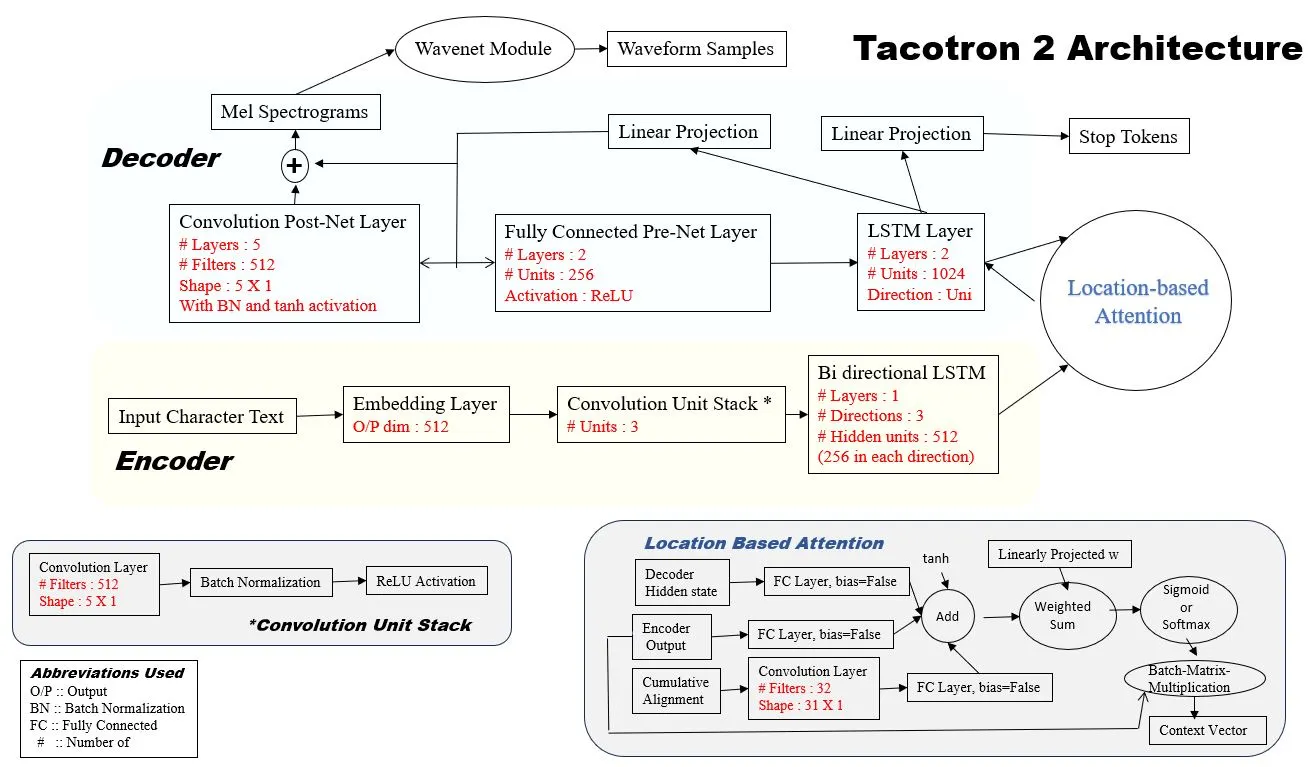

In [21]:
class Encoder(Layer):
    def __init__(self, vocab_size, embedding_dim=512, conv_filters=512, lstm_units=256, **kwargs):
        super(Encoder, self).__init__(**kwargs)
        self.embedding = Embedding(vocab_size, embedding_dim)
        
        # 3-Layer CNN
        self.conv_layers = []
        for _ in range(3):
            self.conv_layers.append(
                Sequential([
                    Conv1D(filters=conv_filters, kernel_size=5, padding='same'),
                    BatchNormalization(),
                    Activation('relu')
                ])
            )
        # Fix 1: Instantiate Dropout in __init__
        self.dropout = Dropout(0.5)
            
        # Bi-Directional LSTM
        self.bi_lstm = Bidirectional(LSTM(lstm_units, return_sequences=True))

    def call(self, inputs, training=False):
        x = self.embedding(inputs)
        
        for conv in self.conv_layers:
            x = conv(x, training=training)
            # Fix 1: Reference the instantiated dropout layer
            x = self.dropout(x, training=training)
            
        encoder_output = self.bi_lstm(x)
        return encoder_output

In [ ]:
class PreNet(Layer):
    def __init__(self, units=256, **kwargs):
        super(PreNet, self).__init__(**kwargs)
        self.dense1 = Dense(units, activation="relu")
        self.dropout1 = Dropout(0.5)
        self.dense2 = Dense(units, activation="relu")
        self.dropout2 = Dropout(0.5)

    def call(self, inputs, training=None):
        x = self.dense1(inputs)
        x = self.dropout1(x, training=True)
        x = self.dense2(x)
        x = self.dropout2(x, training=True)
        return x

In [23]:
class PostNet(Layer):
    def __init__(self, conv_filters=512, mel_channels=80, **kwargs):
        super(PostNet, self).__init__(**kwargs)

        self.conv_layers = []
        for i in range(5):
            act = "tanh" if i < 4 else "linear"
            self.conv_layers.append(
                Sequential([
                    Conv1D(filters=conv_filters if i < 4 else mel_channels, kernel_size=5, padding='same'),
                    BatchNormalization(),
                    Activation(act)
                ])
            )
        self.dropout = Dropout(0.5)

    def call(self, inputs, training=False):
        x = inputs
        for conv in self.conv_layers:
            x = conv(x, training=training)
            x = self.dropout(x, training=training)
        return x

In [24]:
class LocationSensitiveAttention(Layer):
    def __init__(self, attention_dim=128, filters=32, kernel_size=31, **kwargs):
        super(LocationSensitiveAttention, self).__init__(**kwargs)
        
        # 1. Projection for the Decoder Hidden State
        self.query_layer = Dense(attention_dim, use_bias=False)
        
        # 2. Projection for the Encoder Outputs (Text)
        self.memory_layer = Dense(attention_dim, use_bias=False)
        
        # 3. Convolution over [previous_alignment, cumulative_alignment] (2 channels)
        # Wide kernel (31) lets the layer see a broad span of past attention.
        self.location_conv = Conv1D(filters=filters, kernel_size=kernel_size, 
                                    padding='same', use_bias=False)
        
        # 4. Projection for the Location Features
        self.location_layer = Dense(attention_dim, use_bias=False)
        
        # 5. Final layer to calculate the energy score
        self.v = Dense(1, use_bias=False)

    def call(self, query, memory, prev_alignment, cumulative_alignment, memory_mask=None):
        """
        Args:
            query: Decoder hidden state. Shape: (batch_size, decoder_dim)
            memory: Encoder outputs. Shape: (batch_size, max_time, encoder_dim)
            prev_alignment: Attention weights from previous step. Shape: (batch_size, max_time)
            cumulative_alignment: Sum of past attention weights. Shape: (batch_size, max_time)
            memory_mask: Float mask over encoder positions (1.0 valid, 0.0 padding).
                Shape: (batch_size, max_time)
        Returns:
            context_vector: Aligned text representation for this step.
            attention_weights: Weights for this step.
        """
        
        # 1. Project the query
        query = tf.expand_dims(query, 1)                  # (batch, 1, decoder_dim)
        W_query = self.query_layer(query)                 # (batch, 1, attention_dim)

        # 2. Project the memory
        W_memory = self.memory_layer(memory)              # (batch, max_time, attention_dim)

        # 3. Stack two location channels and extract features
        location_features = tf.stack(
            [prev_alignment, cumulative_alignment], axis=-1
        )                                                 # (batch, max_time, 2)
        f = self.location_conv(location_features)         # (batch, max_time, filters)
        W_location = self.location_layer(f)               # (batch, max_time, attention_dim)

        # 4. Energy
        energy = self.v(tf.nn.tanh(W_query + W_memory + W_location))  # (batch, max_time, 1)
        energy = tf.squeeze(energy, axis=-1)              # (batch, max_time)

        # 5. Mask padded encoder positions before softmax
        if memory_mask is not None:
            energy = energy + (1.0 - memory_mask) * -1e9

        # 6. Softmax
        attention_weights = tf.nn.softmax(energy, axis=-1)  # (batch, max_time)

        # 7. Context vector
        context_vector = tf.reduce_sum(
            tf.expand_dims(attention_weights, axis=-1) * memory,
            axis=1
        )                                                  # (batch, encoder_dim)

        return context_vector, attention_weights

In [ ]:
class Decoder(Layer):
    def __init__(self, encoder_dim=512, mel_channels=80, prenet_dim=256, 
                 attention_dim=128, lstm_units=1024, max_inference_steps=1000, **kwargs):
        super(Decoder, self).__init__(**kwargs)

        self.mel_channels = mel_channels
        self.encoder_dim = encoder_dim
        self.max_inference_steps = max_inference_steps
        
        self.prenet = PreNet(units=prenet_dim)
        
        self.lstm_cell_1 = LSTMCell(units=lstm_units)
        self.lstm_cell_2 = LSTMCell(units=lstm_units)
        
        self.attention = LocationSensitiveAttention(attention_dim=attention_dim)
        
        self.mel_projection = Dense(mel_channels)
        self.stop_projection = Dense(1, activation='sigmoid')

    def call(self, encoder_outputs, target_mels=None, memory_mask=None, training=False):
        batch_size = tf.shape(encoder_outputs)[0]
        text_len = tf.shape(encoder_outputs)[1]
        teacher_forcing = target_mels is not None
        
        if teacher_forcing:
            max_steps = tf.shape(target_mels)[1]
        else:
            max_steps = tf.constant(self.max_inference_steps, dtype=tf.int32)
            
        current_mel_frame = tf.zeros(shape=[batch_size, self.mel_channels], dtype=tf.float32)
        current_context_vector = tf.zeros(shape=[batch_size, self.encoder_dim], dtype=tf.float32)
        prev_alignment = tf.zeros(shape=[batch_size, text_len], dtype=tf.float32)
        cumulative_alignment = tf.zeros(shape=[batch_size, text_len], dtype=tf.float32)
        finished = tf.zeros(shape=[batch_size], dtype=tf.bool)
        
        lstm1_state = self.lstm_cell_1.get_initial_state(batch_size=batch_size)
        lstm2_state = self.lstm_cell_2.get_initial_state(batch_size=batch_size)
        
        # dynamic_size so early-break inference doesn't leave zero-filled tail
        predicted_mel_frames = tf.TensorArray(dtype=tf.float32, size=0, dynamic_size=True)
        stop_tokens = tf.TensorArray(dtype=tf.float32, size=0, dynamic_size=True)
        alignments_history = tf.TensorArray(dtype=tf.float32, size=0, dynamic_size=True)

        # Use tf.while_loop so the decoder traces cleanly in graph mode (Keras
        # symbolic tracing doesn't apply autograph to Layer.call, so a Python
        # `for t in tf.range(...)` loop with a tensor-conditional `break`
        # raises "Iterating over a symbolic tf.Tensor is not allowed").
        def cond(t, mel_frame, ctx, prev_a, cum_a, fin, s1, s2, mel_ta, stop_ta, align_ta):
            if teacher_forcing:
                return t < max_steps
            return tf.logical_and(t < max_steps, tf.logical_not(tf.reduce_all(fin)))

        def body(t, mel_frame, ctx, prev_a, cum_a, fin, s1, s2, mel_ta, stop_ta, align_ta):
            # Prenet dropout stays ON at inference too — required by Tacotron 2 for output diversity.
            prenet_out = self.prenet(mel_frame, training=True)

            lstm1_input = tf.concat([prenet_out, ctx], axis=-1)
            lstm1_out, s1 = self.lstm_cell_1(lstm1_input, s1)

            ctx, attention_weights = self.attention(
                query=lstm1_out,
                memory=encoder_outputs,
                prev_alignment=prev_a,
                cumulative_alignment=cum_a,
                memory_mask=memory_mask,
            )
            prev_a = attention_weights
            cum_a = cum_a + attention_weights

            lstm2_input = tf.concat([lstm1_out, ctx], axis=-1)
            lstm2_out, s2 = self.lstm_cell_2(lstm2_input, s2)

            final_concatenation = tf.concat([lstm2_out, ctx], axis=-1)

            predicted_mel_frame = self.mel_projection(final_concatenation)
            stop_token = self.stop_projection(final_concatenation)
            stop_token_squeezed = tf.squeeze(stop_token, axis=-1)

            mel_ta = mel_ta.write(t, predicted_mel_frame)
            stop_ta = stop_ta.write(t, stop_token_squeezed)
            align_ta = align_ta.write(t, attention_weights)

            if teacher_forcing:
                next_mel_frame = target_mels[:, t]
            else:
                next_mel_frame = predicted_mel_frame
                fin = tf.logical_or(fin, stop_token_squeezed > 0.5)

            return (t + 1, next_mel_frame, ctx, prev_a, cum_a, fin,
                    s1, s2, mel_ta, stop_ta, align_ta)

        t0 = tf.constant(0, dtype=tf.int32)
        loop_vars = (t0, current_mel_frame, current_context_vector,
                     prev_alignment, cumulative_alignment, finished,
                     lstm1_state, lstm2_state,
                     predicted_mel_frames, stop_tokens, alignments_history)

        (_, _, _, _, _, _, _, _,
         predicted_mel_frames, stop_tokens, alignments_history) = tf.while_loop(
            cond, body, loop_vars, parallel_iterations=1,
        )

        mel_outputs = predicted_mel_frames.stack()
        stop_tokens_output = stop_tokens.stack()
        alignments = alignments_history.stack()
        
        # Reshape from (time, batch, ...) to (batch, time, ...)
        mel_outputs = tf.transpose(mel_outputs, perm=[1, 0, 2])
        stop_tokens_output = tf.transpose(stop_tokens_output, perm=[1, 0])
        alignments = tf.transpose(alignments, perm=[1, 0, 2])
        
        return mel_outputs, stop_tokens_output, alignments

In [ ]:
class Tacotron2(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim=512, encoder_dim=512, 
                 mel_channels=80, prenet_dim=256, attention_dim=128, 
                 lstm_units=1024, postnet_channels=512, 
                 max_inference_steps=1000, grad_clip_norm=1.0, **kwargs):
        super(Tacotron2, self).__init__(**kwargs)
        
        self.mel_channels = mel_channels
        self.grad_clip_norm = grad_clip_norm
        
        self.encoder = Encoder(
            vocab_size=vocab_size, 
            embedding_dim=embedding_dim, 
            lstm_units=encoder_dim // 2
        )
        self.decoder = Decoder(
            encoder_dim=encoder_dim,
            mel_channels=mel_channels,
            prenet_dim=prenet_dim,
            attention_dim=attention_dim,
            lstm_units=lstm_units,
            max_inference_steps=max_inference_steps,
        )
        self.postnet = PostNet(conv_filters=postnet_channels, mel_channels=mel_channels)
        
    def call(self, inputs, training=None):
        if isinstance(inputs, (list, tuple)):
            text_inputs = inputs[0]
            target_mels = inputs[1]
        else:
            text_inputs = inputs
            target_mels = None
        
        # Build encoder mask from text padding (pad id = 0)
        memory_mask = tf.cast(tf.not_equal(text_inputs, 0), tf.float32)
        
        encoder_outputs = self.encoder(text_inputs, training=training)
        
        mel_outputs, stop_tokens, alignments = self.decoder(
            encoder_outputs, 
            target_mels=target_mels, 
            memory_mask=memory_mask,
            training=training
        )
        
        postnet_residual = self.postnet(mel_outputs, training=training)
        final_mel_outputs = mel_outputs + postnet_residual
        
        return {
            "mel_outputs": mel_outputs,
            "final_mel_outputs": final_mel_outputs,
            "stop_tokens": stop_tokens,
            "alignments": alignments
        }

    def compile(self, optimizer, **kwargs):
        super(Tacotron2, self).compile(**kwargs)
        self.optimizer = optimizer
        self.mel_loss_tracker = tf.keras.metrics.Mean(name="mel_loss")
        self.stop_loss_tracker = tf.keras.metrics.Mean(name="stop_loss")
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")

    @property
    def metrics(self):
        return [self.mel_loss_tracker, self.stop_loss_tracker, self.total_loss_tracker]

    def _compute_losses(self, target_mels, target_stop_tokens, mel_out, final_mel_out, stop_out):
        # Frame mask: 1.0 for real frames (including the final frame whose stop label is 1),
        # 0.0 for everything after the first stop=1 (i.e. padded frames).
        # exclusive cumsum of target_stop_tokens is 0 up to and including the final valid
        # frame, then 1, 2, ... for padded positions.
        frame_mask = tf.cast(
            tf.cumsum(target_stop_tokens, axis=-1, exclusive=True) < 0.5,
            tf.float32,
        )                                                  # (batch, time)
        mel_mask = tf.expand_dims(frame_mask, -1)          # (batch, time, 1)

        n_valid = tf.reduce_sum(frame_mask) + 1e-7
        n_mel_elems = n_valid * tf.cast(tf.shape(mel_out)[-1], tf.float32)

        mel_loss_before = tf.reduce_sum(tf.square(target_mels - mel_out) * mel_mask) / n_mel_elems
        mel_loss_after = tf.reduce_sum(tf.square(target_mels - final_mel_out) * mel_mask) / n_mel_elems
        mel_loss = mel_loss_before + mel_loss_after

        # Manual BCE so reduction is over the time axis (keras.losses.binary_crossentropy
        # would collapse the last axis, giving the wrong shape for masking).
        eps = 1e-7
        stop_clipped = tf.clip_by_value(stop_out, eps, 1.0 - eps)
        stop_bce = -(
            target_stop_tokens * tf.math.log(stop_clipped)
            + (1.0 - target_stop_tokens) * tf.math.log(1.0 - stop_clipped)
        )                                                  # (batch, time)
        stop_loss = tf.reduce_sum(stop_bce * frame_mask) / n_valid

        return mel_loss, stop_loss

    def train_step(self, data):
        x, y = data
        text_inputs, decoder_mel_input = x
        target_mels, target_stop_tokens = y

        with tf.GradientTape() as tape:
            outputs = self((text_inputs, decoder_mel_input), training=True)
            
            mel_out = outputs["mel_outputs"]
            final_mel_out = outputs["final_mel_outputs"]
            stop_out = outputs["stop_tokens"]
            
            mel_loss, stop_loss = self._compute_losses(
                target_mels, target_stop_tokens, mel_out, final_mel_out, stop_out
            )
            total_loss = mel_loss + stop_loss
            
            # MirroredStrategy sums gradients across replicas. Each replica computes a
            # per-replica mean already, so divide by replica count to recover the global mean.
            num_replicas = tf.cast(
                tf.distribute.get_strategy().num_replicas_in_sync, tf.float32
            )
            scaled_loss = total_loss / num_replicas

        grads = tape.gradient(scaled_loss, self.trainable_variables)
        # Tacotron 2 paper clips global gradient norm to 1.0
        grads, _ = tf.clip_by_global_norm(grads, self.grad_clip_norm)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))

        self.mel_loss_tracker.update_state(mel_loss)
        self.stop_loss_tracker.update_state(stop_loss)
        self.total_loss_tracker.update_state(total_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "mel_loss": self.mel_loss_tracker.result(),
            "stop_loss": self.stop_loss_tracker.result(),
        }

In [27]:
import os
import pandas as pd
import numpy as np
import scipy.io.wavfile as wavfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
import librosa
import tensorflow as tf


SAMPLE_RATE = 22050
N_FFT = 1024
HOP_LENGTH = 256
WIN_LENGTH = 1024
N_MELS = 80

# Precompute Mel Filterbank matrix and Hanning window to avoid recalculating in loops
MEL_BASIS = librosa.filters.mel(sr=SAMPLE_RATE, n_fft=N_FFT, n_mels=N_MELS).astype(np.float32)
WINDOW = np.hanning(WIN_LENGTH).astype(np.float32)

vocab = " abcdefghijklmnopqrstuvwxyz'.?!" # Index 0 is reserved for padding
char_to_id = {char: idx + 1 for idx, char in enumerate(vocab)}
VOCAB_SIZE = len(char_to_id) + 1  # +1 for the pad id

MEL_CACHE_DIR = "/kaggle/working/mel_cache"
wav_dir = "/kaggle/input/datasets/awsaf49/ljspeech-sr16k-dataset/wavs"
metadata_path = "/kaggle/input/datasets/awsaf49/ljspeech-sr16k-dataset/metadata.csv"

def text_to_sequence(text):
    text = text.lower()
    return np.array([char_to_id[c] for c in text if c in char_to_id], dtype=np.int32)


def fast_wav_to_mel(wav_path):
    sr, y = wavfile.read(wav_path)
    
    # Normalize integer audio frames to [-1.0, 1.0] float32
    if y.dtype == np.int16:
        y = y.astype(np.float32) / 32768.0
    elif y.dtype == np.int32:
        y = y.astype(np.float32) / 2147483648.0
        
    # Reflect pad signal to match standard librosa output structure
    padding = N_FFT // 2
    y_padded = np.pad(y, padding, mode='reflect')
    
    # Rapid strided 1D framing (zero memory copy sliding window)
    n_frames = 1 + (len(y_padded) - WIN_LENGTH) // HOP_LENGTH
    frames = np.lib.stride_tricks.as_strided(
        y_padded, 
        shape=(n_frames, WIN_LENGTH), 
        strides=(y_padded.strides[0] * HOP_LENGTH, y_padded.strides[0]),
        writeable=False
    )
    
    # Multiply window and compute Real FFT (faster and uses half the memory of standard FFT)
    windowed_frames = frames * WINDOW
    stft_matrix = np.fft.rfft(windowed_frames, n=N_FFT)
    magnitude = np.abs(stft_matrix).T # Shape: (frequency_bins, time_frames)
    
    # Project to Mel scale and apply log scale compression
    mel_spectrogram = np.dot(MEL_BASIS, magnitude)
    log_mel = np.log(np.maximum(1e-5, mel_spectrogram)).T # Shape: (time_frames, n_mels)
    
    return log_mel.astype(np.float32)


def _precompute_one(args):
    """Worker: extract one mel and write it as a serialized TF tensor.

    Threads (not processes) are fine here because numpy's FFT / matmul / I/O
    all release the GIL — and threads avoid having to re-pickle MEL_BASIS/WINDOW
    into worker processes."""
    wav_path, out_path = args
    if os.path.exists(out_path):
        return  # idempotent: skip files we've already computed
    mel = fast_wav_to_mel(wav_path)
    serialized = tf.io.serialize_tensor(tf.constant(mel)).numpy()
    # Write atomically via a tmp path so an interrupted run doesn't leave half-written files.
    tmp_path = out_path + ".tmp"
    with open(tmp_path, "wb") as f:
        f.write(serialized)
    os.replace(tmp_path, out_path)

def precompute_mels(jobs, max_workers=8):
    os.makedirs(MEL_CACHE_DIR, exist_ok=True)
    todo = [j for j in jobs if not os.path.exists(j[1])]
    if not todo:
        print(f"Mel cache hit: all {len(jobs)} files already on disk.")
        return
    print(f"Precomputing {len(todo)} mels (cache had {len(jobs) - len(todo)})...")
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        for _ in tqdm(ex.map(_precompute_one, todo), total=len(todo)):
            pass


def get_ljspeech_dataset(batch_size=32):
    df = pd.read_csv(metadata_path)
    print(len(df))

    # Build the (mel_cache_path, text_seq) list and the precompute job list in one pass.
    samples = []
    precompute_jobs = []
    for _, row in df.iterrows():
        wav_path = os.path.join(wav_dir, row['file_name'])
        stem = os.path.splitext(row['file_name'])[0]
        mel_cache_path = os.path.join(MEL_CACHE_DIR, f"{stem}.mel")
        samples.append((mel_cache_path, text_to_sequence(row['sentence'])))
        precompute_jobs.append((wav_path, mel_cache_path))

    print("Total Samples: ", len(samples))

    # Run mel extraction once (no-op on subsequent epochs / kernel restarts).
    precompute_mels(precompute_jobs)

    def generator():
        for mel_path, seq in samples:
            yield mel_path, seq

    raw_dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(), dtype=tf.string),
            tf.TensorSpec(shape=(None,), dtype=tf.int32),
        )
    )

    def load_example(mel_path, text_seq):
        # Pure-TF load: tf.io.read_file + tf.io.parse_tensor → no GIL, so
        # num_parallel_calls=AUTOTUNE genuinely parallelizes across CPU threads.
        raw = tf.io.read_file(mel_path)
        mel = tf.io.parse_tensor(raw, out_type=tf.float32)
        mel.set_shape([None, N_MELS])

        # Stop token: 0.0 everywhere except the final frame.
        mel_len = tf.shape(mel)[0]
        stop_token = tf.concat(
            [tf.zeros([mel_len - 1], dtype=tf.float32),
             tf.ones([1], dtype=tf.float32)],
            axis=0,
        )
        stop_token.set_shape([None])
        text_seq.set_shape([None])

        # x = (text, mel_input)   y = (mel_target, stop_token)
        return (text_seq, mel), (mel, stop_token)

    dataset = raw_dataset.map(load_example, num_parallel_calls=tf.data.AUTOTUNE)

    # Cache loaded mels in RAM so epoch 2+ does zero disk I/O.
    # If memory is tight, swap to .cache("/kaggle/working/ds_cache") for disk caching instead.
    dataset = dataset.cache()

    dataset = dataset.shuffle(buffer_size=500)

    # Dynamic padding to the longest sequence in each batch.
    # Padding values are arbitrary for mel/decoder input because the loss masks
    # padded frames out using the stop-token cumsum; pad stop tokens with 1.0
    # so the mask correctly identifies them as "past end of audio".
    dataset = dataset.padded_batch(
        batch_size=batch_size,
        padded_shapes=(
            ([None], [None, N_MELS]),
            ([None, N_MELS], [None])
        ),
        padding_values=(
            (tf.constant(0, dtype=tf.int32), tf.constant(-11.5, dtype=tf.float32)),
            (tf.constant(-11.5, dtype=tf.float32), tf.constant(1.0, dtype=tf.float32))
        ),
        drop_remainder=True,  # keep batch sizes uniform across replicas
    )

    # Prefetch data so the CPU calculates the next batch while the GPU trains the current one
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    
    return dataset

In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

class AttentionPlotCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_text, char_to_id, save_dir="/kaggle/working/alignments"):
        super(AttentionPlotCallback, self).__init__()
        self.validation_text = validation_text
        self.char_to_id = char_to_id
        self.save_dir = save_dir
        
        # Convert the string sentence into token integers
        tokens = [char_to_id[c] for c in validation_text.lower() if c in char_to_id]
        # Expand dims to represent a batch of size 1: (1, text_len)
        self.tokens_tensor = tf.convert_to_tensor(np.expand_dims(tokens, axis=0))
        
        # Ensure the output directory exists
        os.makedirs(self.save_dir, exist_ok=True)
        
    def on_epoch_end(self, epoch, logs=None):
        # Python epoch index is 0-indexed, so epoch + 1 matches standard numbering
        current_epoch = epoch + 1
        
        # Trigger plot generation every 10 epochs
        if current_epoch % 10 == 0:
            # 1. Run inference pass on our validation text
            # Setting training=False prevents using teacher forcing
            outputs = self.model(self.tokens_tensor, training=False)
            
            # 2. Extract attention alignment weights 
            # Output shape: (batch, decoder_steps, encoder_steps) -> we take [0] for batch 1
            alignments = outputs["alignments"].numpy()[0] # Shape: (max_steps, text_len)
            
            # 3. Plot the attention heatmap
            fig, ax = plt.subplots(figsize=(10, 8))
            
            # We transpose (alignments.T) to place characters on Y-axis and time on X-axis
            im = ax.imshow(
                alignments.T, 
                aspect='auto', 
                origin='lower', 
                cmap='hot', 
                interpolation='none'
            )
            
            # Label configuration
            ax.set_xlabel("Decoder Steps (Audio frames)")
            ax.set_ylabel("Encoder Steps (Text characters)")
            ax.set_title(f"Attention Alignment - Epoch {current_epoch}")
            fig.colorbar(im, ax=ax)
            
            # Align tick-marks on Y-axis directly with our validation characters
            ax.set_yticks(range(len(self.validation_text)))
            ax.set_yticklabels(list(self.validation_text))
            
            # Save the heatmap figure
            filepath = os.path.join(self.save_dir, f"alignment_epoch_{current_epoch}.png")
            plt.savefig(filepath, bbox_inches='tight')
            plt.close(fig)
            
            print(f"\n[AttentionPlotCallback] Attention map written to {filepath}")

In [29]:
strategy = tf.distribute.MirroredStrategy()
num_gpus = strategy.num_replicas_in_sync
print(f"Number of active devices: {num_gpus}")

# Scale batch size for distributed replica execution
BATCH_SIZE_PER_REPLICA = 16
GLOBAL_BATCH_SIZE = BATCH_SIZE_PER_REPLICA * num_gpus
print(f"Global Batch Size: {GLOBAL_BATCH_SIZE}")


dataset = get_ljspeech_dataset(batch_size=GLOBAL_BATCH_SIZE)

# vocab_size = (num real tokens) + 1 for the reserved pad id (0)
vocab_size = VOCAB_SIZE

with strategy.scope():
    # Instantiate the Tacotron 2 model
    model = Tacotron2(vocab_size=vocab_size)
    
    # Tacotron 2 paper: Adam @ 1e-3 with exponential decay starting at step 50k.
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=50000,
        decay_rate=0.5,
        staircase=False,
    )
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)
    model.compile(optimizer=optimizer)
    
    # Dry-run dummy inputs inside the strategy scope to build layer shapes.
    # Use minval=1 so we never hit the pad id (encoder mask would zero everything).
    dummy_text = tf.random.uniform((2, 10), minval=1, maxval=vocab_size, dtype=tf.int32)
    dummy_mel = tf.random.uniform((2, 50, 80), dtype=tf.float32)
    _ = model((dummy_text, dummy_mel))
    
    # Print the model parameters summary
    model.summary()

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of active devices: 2
Global Batch Size: 32
13100
Total Samples:  13100
Precomputing 13100 mels (cache had 0)...


  0%|          | 0/13100 [00:00<?, ?it/s]

I0000 00:00:1779600855.921083      57 cuda_dnn.cc:529] Loaded cuDNN version 91002


Model: "tacotron2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Encoder)               │ ?                      │     5,531,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Decoder)               │ ?                      │    18,247,825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ post_net (PostNet)              │ ?                      │     4,352,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,131,361 (107.31 MB)

 Trainable params: 28,124,033 (107.28 MB)

 Non-trainable params: 7,328 (28.62 KB)

In [30]:
validation_sentence = "the quick brown fox jumps."

# Initialize the plotting callback
attention_callback = AttentionPlotCallback(
    validation_text=validation_sentence,
    char_to_id=char_to_id
)

model.fit(dataset, epochs=20, callbacks=[attention_callback])

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1779600874.369097     102 cuda_dnn.cc:529] Loaded cuDNN version 91002


      8/Unknown 53s 4s/step - loss: 37.7114 - mel_loss: 37.5001 - stop_loss: 0.2114

KeyboardInterrupt: 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


...


      9/Unknown 71s 5s/step - loss: 36.2663 - mel_loss: 36.0457 - stop_loss: 0.2206


     10/Unknown 77s 5s/step - loss: 34.4792 - mel_loss: 34.2718 - stop_loss: 0.2074


     11/Unknown 82s 5s/step - loss: 32.9164 - mel_loss: 32.7204 - stop_loss: 0.1960


     12/Unknown 88s 5s/step - loss: 31.5371 - mel_loss: 31.3510 - stop_loss: 0.1860


     13/Unknown 93s 5s/step - loss: 30.3116 - mel_loss: 30.1343 - stop_loss: 0.1773